In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, Function, Eq, dsolve, lambdify, exp

In [2]:
t = symbols('t', positive=True)
V = 100
c_in = 0.5
q = 5

In [3]:
m = Function('m')
ode = Eq(m(t).diff(t) + (q/V)*m(t), c_in*q)
ode

Eq(0.05*m(t) + Derivative(m(t), t), 2.5)

In [4]:
solution = dsolve(ode, m(t), ics={m(0): 0})
solution

Eq(m(t), 50.0 - 50.0*exp(-0.05*t))

In [5]:
m_t_expr = solution.rhs
m_func = lambdify(t, m_t_expr, 'numpy')
t_vals = np.linspace(0, 200, 500)
m_vals = m_func(t_vals)

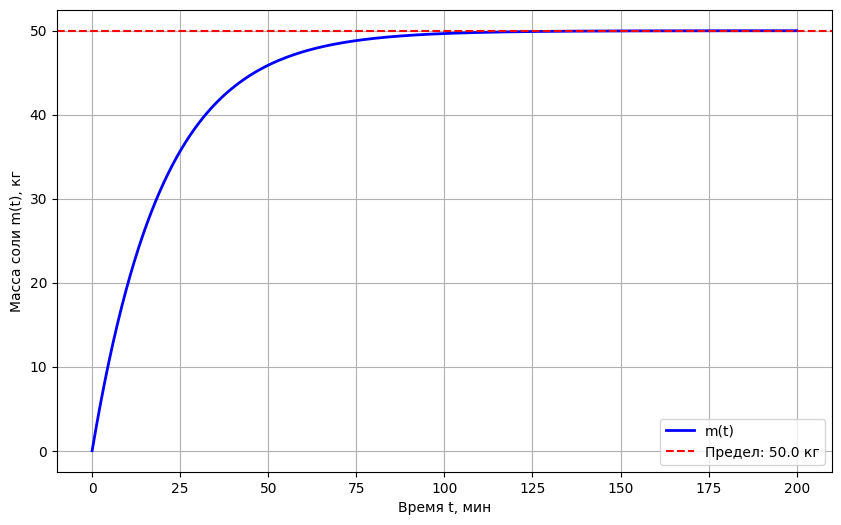

In [6]:

plt.figure(figsize=(10, 6))
plt.plot(t_vals, m_vals, label=r'm(t)', color='blue', linewidth=2)
limit_mass = c_in * V
plt.axhline(y = limit_mass, color='red', linestyle='--', label=f'Предел: {limit_mass} кг')
plt.xlabel('Время t, мин')
plt.ylabel('Масса соли m(t), кг')
plt.grid(True)
plt.legend()
plt.show()

а) К какому пред. стремится и почему

In [7]:
print(f"При t стрем. к беск., слагаемое exp(-t/20) стремится к 0. Следовательно, предел m(t) = c_in * V = {limit_mass} кг. В баке устанавливается динамическое равновесие. Сколько соли вливается в минуту (приток), столько же и выливается (отток).")

При t стрем. к беск., слагаемое exp(-t/20) стремится к 0. Следовательно, предел m(t) = c_in * V = 50.0 кг. В баке устанавливается динамическое равновесие. Сколько соли вливается в минуту (приток), столько же и выливается (отток).


б)За какое время соли станет 90% от предельной

In [8]:
target_mass = 0.9 * limit_mass
print(f"90% от предельной массы = {target_mass} кг")

f = Function('f')
ode_log = Eq(f(t).diff(t), 1/t)
sol_log = dsolve(ode_log, f(t), ics={f(t).subs(t, 1): 0})
log_01 = sol_log.rhs.subs(t, 0.1)
t_90_val = float(-(V / q) * log_01)
print(f"Соли станет 90% от предельной через t = {t_90_val:.2f} мин.")

90% от предельной массы = 45.0 кг
Соли станет 90% от предельной через t = 46.05 мин.
